# Citizen Science Profile

Visualizes the standardized profile of a citizen science project. Run the cells top to bottom: the first sets the color theme. Every chart then has two code cells: the first is where you enter the numbers for your project (the comments explain what they mean), the second draws the chart from them.

In [22]:
# Theme: pick the color family used by all charts (pumpkin, apricot, apple, teal, blueberry, eggplant, dragonfruit)
COLOR_FAMILY = "pumpkin"
PALETTE_FILE = "colorpalette.json"  # path to the palette file, relative to the notebook
OUTPUT_DIR = "output"  # folder the chart PNGs are saved to, relative to the notebook

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

with open(Path(PALETTE_FILE)) as f:
    _data = json.load(f)
OUTPUT_PATH = Path(OUTPUT_DIR)
OUTPUT_PATH.mkdir(exist_ok=True)

palette = _data["palettes"]
type_colors = _data["assignments"]["Project type (Wiggins and Crowston)"]["colors"]

families = palette["Color families"]
neutrals = palette["Neutrals"]


def shade(name, family=None):
    """Hex of one shade (lighter, light, base, dark, darker) of a color family."""
    family = family or COLOR_FAMILY
    return families["families"][family][families["shades"].index(name)]


def neutral(role):
    """Hex of a neutral role (background, gridline, axis, text, ...) via the grey ramp."""
    return neutrals["ramp"][neutrals["roles"][role]]


plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["figure.dpi"] = 150  # sharper inline preview; at low dpi the text gets wider and labels collide
print(f"Theme: {COLOR_FAMILY}", {s: shade(s) for s in families["shades"]})

Theme: pumpkin {'lighter': '#F7C9B8', 'light': '#EE7A56', 'base': '#D04C2D', 'dark': '#95331E', 'darker': '#521F11'}


## Project type

Wiggins and Crowston [16]: five project types: *action*, *conservation*, *investigation*, *virtual* and *education*.

Input is one value from 0 to 100 per type, drawn as a circular bar chart. Each type has a fixed color from the palette file, and every type keeps its slot (a faint track) even when its value is 0. Every color can be overridden.

In [23]:
# INPUT: project type (Wiggins and Crowston [16])
# Score how much your project matches each type, from 0 (not at all) to 100 (completely).
# The types are not exclusive: a project can score high on several, or 0 on some.
project_types = {
    "action": 70,         # participants take action on local concerns; social action is the emphasis
    "conservation": 40,   # supports natural resource management and conservation goals
    "investigation": 85,  # scientific research goals that need data collected in the physical environment
    "virtual": 0,         # all activity is online or through technology, no physical-environment data
    "education": 0,       # education and outreach is the primary goal
}

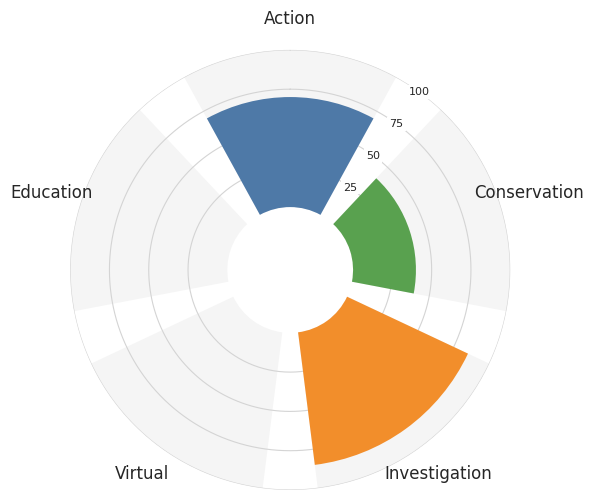

In [24]:
PROJECT_TYPES = ["action", "conservation", "investigation", "virtual", "education"]


def plot_project_type_chart(
    values,
    colors=None,          # {type: hex}; default: fixed project type colors from the palette file
    background="white",
    track_color=None,     # full-length slot behind each bar; default: lightest grey
    ring_color=None,      # circles at 25/50/75/100; default: light grey
    text_color=None,      # labels; default: neutral text
    hole=40,              # empty center, in value units
    label_size=12,        # font size of the type labels
    figsize=(6, 6),
    ax=None,             # draw into this axes instead of a new figure (used by the combined figure)
    save_to=None,
):
    """Circular bar chart of the five Wiggins and Crowston project types.

    values: dict {type: 0-100} with all five types.
    """
    missing = [t for t in PROJECT_TYPES if t not in values]
    extra = [t for t in values if t not in PROJECT_TYPES]
    if missing or extra:
        raise ValueError(f"Expected exactly {PROJECT_TYPES}; missing {missing}, unexpected {extra}")
    if not all(0 <= values[t] <= 100 for t in PROJECT_TYPES):
        raise ValueError("All values must be between 0 and 100")

    colors = {**type_colors, **(colors or {})}
    ramp = palette["Neutrals"]["ramp"]
    track_color = track_color or ramp["grey-100"]
    ring_color = ring_color or ramp["grey-300"]
    text_color = text_color or neutral("text")

    n = len(PROJECT_TYPES)
    slot = 2 * np.pi / n
    width = slot * 0.8  # leaves a gap between bars
    angles = np.arange(n) * slot

    standalone = ax is None
    if standalone:
        fig, ax = plt.subplots(figsize=figsize, subplot_kw={"projection": "polar"})
    else:
        fig = ax.figure  # must be a polar axes
    fig.patch.set_facecolor(background)
    ax.set_facecolor(background)
    ax.set_theta_offset(np.pi / 2)  # first type at the top
    ax.set_theta_direction(-1)      # clockwise
    ax.set_ylim(0, hole + 100)

    ax.grid(False)
    ax.spines["polar"].set_visible(False)
    ax.set_yticks([])

    # tracks keep every type visible, also at 0
    ax.bar(angles, [100] * n, width=width, bottom=hole, color=track_color, linewidth=0, zorder=0)

    # rings with labels sitting on the line, in the gap between two bars
    theta = np.linspace(0, 2 * np.pi, 361)
    label_angle = angles[0] + slot / 2
    for r in (25, 50, 75, 100):
        ax.plot(theta, [hole + r] * len(theta), color=ring_color, linewidth=0.8, zorder=1)
        ax.text(label_angle, hole + r, str(r), ha="center", va="center", fontsize=label_size * 0.67, color=text_color,
                bbox=dict(facecolor=background, edgecolor="none", pad=1.5), zorder=4)

    ax.bar(angles, [values[t] for t in PROJECT_TYPES], width=width, bottom=hole,
           color=[colors[t] for t in PROJECT_TYPES], linewidth=0, zorder=2)

    ax.set_xticks(angles)
    ax.set_xticklabels([t.capitalize() for t in PROJECT_TYPES], color=text_color, fontsize=label_size)
    ax.tick_params(axis="x", pad=label_size)

    if standalone:
        fig.tight_layout()
    if save_to:
        fig.savefig(save_to, dpi=200, facecolor=fig.get_facecolor(), bbox_inches="tight")
    return fig, ax


fig, ax = plot_project_type_chart(project_types, save_to=OUTPUT_PATH / "project_type_chart.png")
plt.show()

## Environmental monitoring campaigns

After Pocock, Tweddle, Savage, et al. [ref]. Only for environmental monitoring campaigns.

The project is placed on two axes: **simple approach → elaborate approach** (vertical) and **systematic monitoring → mass participation** (horizontal). Input is one value from 0 to 100 for each axis: `x` runs from systematic monitoring (0) to mass participation (100), `y` from simple approach (0) to elaborate approach (100).

The grey points in the background mimic the distribution of the papers analysed by Pocock, Tweddle, Savage et al., so you can see where your project sits relative to them. Their positions are in `data/pocock_background_points.csv`; only the points marked `no` in its `computer based` column are drawn. By default the project is drawn in the theme color. Every color can be overridden.

In [25]:
# INPUT: position on Pocock's two axes (environmental monitoring campaigns only)
# Both values run from 0 to 100.
pocock_x = 25  # 0 = systematic monitoring (set protocols, trained or selected volunteers)
               # 100 = mass participation (open to anyone, many participants, little training)
pocock_y = 60  # 0 = simple approach (few, easy tasks, low demands on participants)
               # 100 = elaborate approach (many or demanding tasks, more skills and effort required)

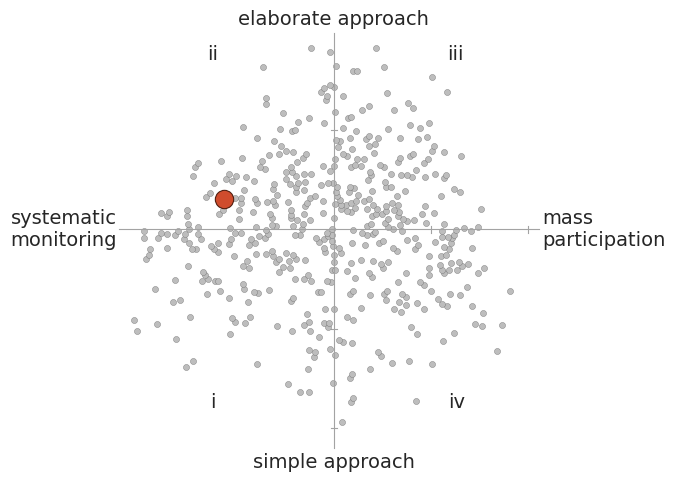

In [26]:
import csv

with open("data/pocock_background_points.csv") as f:
    pocock_points = np.array([[float(r["x"]), float(r["y"])]
                              for r in csv.DictReader(f) if r["computer based"] == "no"])

# plot extent in the units of the background points
POCOCK_XLIM = (-4.50, 4.29)
POCOCK_YLIM = (-4.58, 4.11)


def plot_pocock_chart(
    x,
    y,
    background="white",
    point_color=None,      # background points; default: grey
    point_edge=None,
    highlight_color=None,  # your project; default: theme "base"
    highlight_edge=None,   # default: theme "darker"
    axis_color=None,       # default: grey
    text_color=None,       # default: neutral text
    label_size=14,         # font size of the axis and quadrant labels
    figsize=(7, 7),
    ax=None,             # draw into this axes instead of a new figure (used by the combined figure)
    save_to=None,
):
    """Place a project on Pocock et al.'s two axes.

    x: 0 (systematic monitoring) to 100 (mass participation)
    y: 0 (simple approach) to 100 (elaborate approach)
    """
    if not (0 <= x <= 100 and 0 <= y <= 100):
        raise ValueError("x and y must be between 0 and 100")

    ramp = palette["Neutrals"]["ramp"]
    point_color = point_color or ramp["grey-400"]
    point_edge = point_edge or ramp["grey-600"]
    highlight_color = highlight_color or shade("base")
    highlight_edge = highlight_edge or shade("darker")
    axis_color = axis_color or ramp["grey-500"]
    text_color = text_color or neutral("text")

    (x0, x1), (y0, y1) = POCOCK_XLIM, POCOCK_YLIM
    px = x0 + x / 100 * (x1 - x0)
    py = y0 + y / 100 * (y1 - y0)

    standalone = ax is None
    if standalone:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure
    fig.patch.set_facecolor(background)
    ax.set_facecolor(background)
    ax.set_xlim(x0, x1)
    ax.set_ylim(y0, y1)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xticks([])
    ax.set_yticks([])

    # axes cross in the middle
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_position("zero")
        ax.spines[side].set_color(axis_color)
        ax.spines[side].set_linewidth(0.8)

    # small tick marks
    for tx in (2.04, 4.06):
        ax.plot([tx, tx], [-0.07, 0.07], color=axis_color, linewidth=0.8)
    for ty in (2.075, -2.075, -4.155):
        ax.plot([-0.07, 0.07], [ty, ty], color=axis_color, linewidth=0.8)

    # axis labels
    label = dict(fontsize=label_size, color=text_color, annotation_clip=False)
    ax.annotate("elaborate approach", (0, 4.2), ha="center", va="bottom", **label)
    ax.annotate("simple approach", (0, -4.68), ha="center", va="top", **label)
    ax.annotate("systematic\nmonitoring", (-4.55, 0), ha="right", va="center", linespacing=1.2, **label)
    ax.annotate("mass\nparticipation", (4.35, 0), ha="left", va="center", linespacing=1.2, **label)

    # quadrant labels
    for text, (qx, qy) in {"ii": (-2.54, 3.66), "iii": (2.55, 3.66), "i": (-2.54, -3.61),
                           "iv": (2.56, -3.61)}.items():
        ax.text(qx, qy, text, ha="center", va="center", fontsize=label_size, color=text_color)

    # background: distribution of the analysed papers
    ax.scatter(pocock_points[:, 0], pocock_points[:, 1], s=19 * (label_size / 14) ** 2, color=point_color,
               edgecolor=point_edge, linewidth=0.3, zorder=2)
    # the project
    ax.scatter([px], [py], s=174 * (label_size / 14) ** 2, color=highlight_color, edgecolor=highlight_edge,
               linewidth=0.8, zorder=3)

    if standalone:
        fig.subplots_adjust(left=0.2, right=0.8, bottom=0.1, top=0.9)
    if save_to:
        fig.savefig(save_to, dpi=200, facecolor=fig.get_facecolor(), bbox_inches="tight")
    return fig, ax


fig, ax = plot_pocock_chart(x=pocock_x, y=pocock_y, save_to=OUTPUT_PATH / "pocock_chart.png")
plt.show()

## Participation depth

Haklay [ref]: four levels of participant involvement: *crowdsourcing*, *distributed intelligence*, *participatory science* and *extreme citizen science*.

Input is one position from 1 to 10, drawn as ten growing bars: the four levels sit at 1, 4, 7 and 10, and the two steps between each pair of levels (2 and 3, 5 and 6, 8 and 9) are for projects that fall in between. The bars up to the project's position are filled with the theme color family, light for crowdsourcing to dark for extreme citizen science, and the rest stay grey. Every color can be overridden.

In [27]:
# INPUT: depth of participation (Haklay [ref])
# One whole number from 1 to 10. The four levels sit at 1, 4, 7 and 10; the steps in between
# (2-3, 5-6, 8-9) are for projects that fall between two levels.
#   1  = crowdsourcing: participants act as sensors or provide computing resources,
#        with limited involvement in defining the research
#   4  = distributed intelligence: participants contribute their cognitive abilities, e.g. classifying,
#        interpreting or processing information, often after basic training
#   7  = participatory science: participants help define the research problem and what data to collect,
#        typically together with scientific experts
#   10 = extreme citizen science: participants are involved in problem definition, data collection and analysis
# 2-3 lie between crowdsourcing and distributed intelligence, 5-6 between distributed intelligence and
# participatory science, 8-9 between participatory science and extreme citizen science.
participation_depth = 5

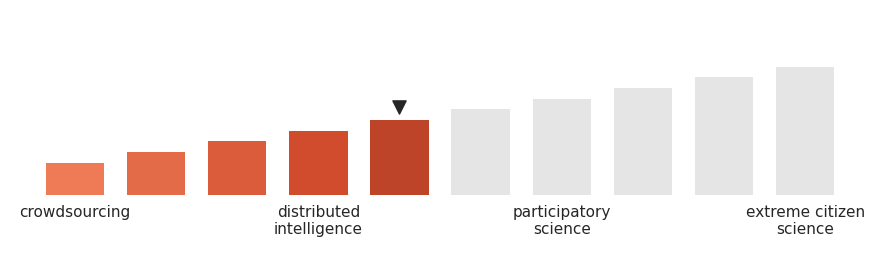

In [28]:
import textwrap
from matplotlib.colors import LinearSegmentedColormap

DEPTH_LEVELS = ["crowdsourcing", "distributed intelligence", "participatory science", "extreme citizen science"]
DEPTH_POSITIONS = 10
LEVEL_POSITIONS = [1, 4, 7, 10]  # the positions in between are 2-3, 5-6 and 8-9


def plot_participation_depth_chart(
    position,
    colors=None,         # {level: hex}; default: theme shades light, base, dark, darker, steps in between interpolated
    empty_color=None,    # bars beyond the position; default: light grey
    marker_color=None,   # default: neutral text
    background="white",
    text_color=None,     # default: neutral text
    label_size=11,       # font size of the level labels
    figsize=(9, 2.8),
    ax=None,             # draw into this axes instead of a new figure (used by the combined figure)
    save_to=None,
):
    """Ten growing bars, filled up to one of ten positions between the four Haklay levels.

    position: whole number from 1 (crowdsourcing) to 10 (extreme citizen science).
    """
    if position != int(position) or not 1 <= position <= DEPTH_POSITIONS:
        raise ValueError(f"position must be a whole number from 1 to {DEPTH_POSITIONS}")
    position = int(position)

    colors = {**dict(zip(DEPTH_LEVELS, (shade(s) for s in ("light", "base", "dark", "darker")))), **(colors or {})}
    empty_color = empty_color or palette["Neutrals"]["ramp"]["grey-200"]
    text_color = text_color or neutral("text")
    marker_color = marker_color or text_color

    # one color per position, interpolated between the four level colors
    cmap = LinearSegmentedColormap.from_list("depth", [colors[level] for level in DEPTH_LEVELS])
    xs = np.arange(1, DEPTH_POSITIONS + 1)
    heights = 0.25 + 0.75 * (xs - 1) / (DEPTH_POSITIONS - 1)
    fills = [cmap((p - 1) / (DEPTH_POSITIONS - 1)) if p <= position else empty_color for p in xs]

    standalone = ax is None
    if standalone:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure
    fig.patch.set_facecolor(background)
    ax.set_facecolor(background)
    ax.set_xlim(0.2, 10.8)
    ax.set_ylim(-0.5, 1.45)
    ax.axis("off")

    ax.bar(xs, heights, width=0.72, color=fills, linewidth=0, zorder=2)

    # marker above the bar at the project's position
    ax.scatter([position], [heights[position - 1] + 0.1], marker="v", s=90, color=marker_color, zorder=3)

    for p, level in zip(LEVEL_POSITIONS, DEPTH_LEVELS):
        ax.text(p, -0.07, "\n".join(textwrap.wrap(level, 16)), ha="center", va="top", fontsize=label_size,
                color=text_color, linespacing=1.2)

    if standalone:
        fig.tight_layout()
    if save_to:
        fig.savefig(save_to, dpi=200, facecolor=fig.get_facecolor(), bbox_inches="tight")
    return fig, ax


fig, ax = plot_participation_depth_chart(position=participation_depth, save_to=OUTPUT_PATH / "participation_depth_chart.png")
plt.show()

## Project profile at a glance

All three charts in one figure for a paper: (a) project type, (b) Pocock's axes, (c) depth of participation. Uses the inputs above; saved as PNG and PDF (vector) in the output folder.

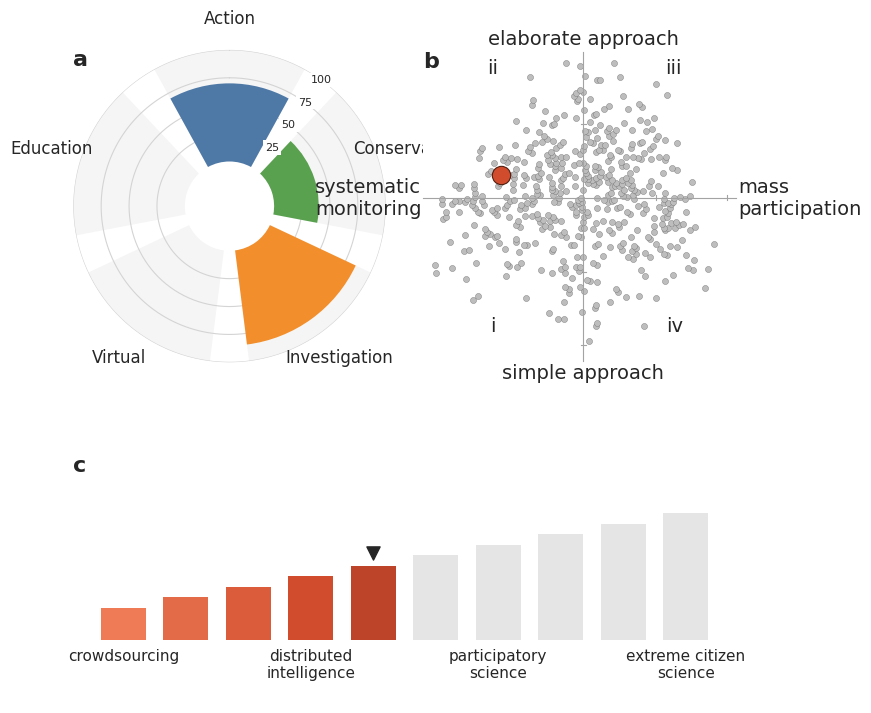

In [29]:
def plot_profile_overview(
    project_types,
    pocock_xy,
    depth,
    background="white",
    title=None,
    figsize=(7.2, 5.6),   # about double-column width in inches
    save_to=None,         # PNG path; a PDF with the same name is saved next to it
):
    """Project profile on one page: (a) project type and (b) Pocock's axes on top, (c) participation depth below."""
    text_color = neutral("text")

    fig = plt.figure(figsize=figsize, facecolor=background)
    grid = fig.add_gridspec(2, 2, height_ratios=[2.3, 1], hspace=0.02, wspace=0.7,
                            left=0.04, right=0.96, top=0.92 if title else 0.96, bottom=0.03)
    ax_a = fig.add_subplot(grid[0, 0], projection="polar")
    ax_b = fig.add_subplot(grid[0, 1])
    ax_c = fig.add_subplot(grid[1, :])

    plot_project_type_chart(project_types, background=background, ax=ax_a, label_size=9)
    plot_pocock_chart(*pocock_xy, background=background, ax=ax_b, label_size=9)
    plot_participation_depth_chart(depth, background=background, ax=ax_c, label_size=9)

    for ax, letter in ((ax_a, "a"), (ax_b, "b"), (ax_c, "c")):
        ax.text(0, 1, letter, transform=ax.transAxes, fontsize=16, fontweight="bold",
                color=text_color, ha="left", va="top")
    if title:
        fig.suptitle(title, fontsize=14, color=text_color)

    if save_to:
        save_to = Path(save_to)
        for suffix in (".png", ".pdf"):
            fig.savefig(save_to.with_suffix(suffix), dpi=300, facecolor=fig.get_facecolor(), bbox_inches="tight")
    return fig, (ax_a, ax_b, ax_c)


fig, axes = plot_profile_overview(project_types, (pocock_x, pocock_y), participation_depth,
                                  save_to=OUTPUT_PATH / "project_profile.png")
plt.show()
